In [ ]:
# have the original dataframe 
# analyze null values for each using the dataframe
# analyze hit rates for that using the dataframe 
# compile a list of valid_indices
# get the final valid dataframe

In [194]:
import scipy.io 
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
import pickle as pl
from collections import OrderedDict
import traceback
import random
import threading
import math
import os

In [ ]:
# we shoudl see how much vt is actually covering

### Exploring the structure one mat file

#### Validating vt, birth time , age death 
##### first valdiate that the vt[-1] and vt[0] is within 0, 86,400*age_of_death 
##### see the idfference 64,000*age_of_death  - vt[-1] 
##### since we care about < 1, <3 , <5 day, its better to see the gap between vt[-1] and age of death rather than birht time and vt[0]

In [ ]:
# Validate timestamps and calculate difference from death
validation_results = []

for file_path in mat_files[:50]:
    mat_data = scipy.io.loadmat(file_path)
    baby_id = file_path.split('/')[-1].split('_')[1]
    
    # Get timestamps
    vt = mat_data['vt'].flatten()
    vt_first = vt[0]
    vt_last = vt[-1]
    
    # Get birth time and age at death
    birth_time = mat_data['pdata'][0][1]
    age_at_death = mat_data['pdata'][0][-1]
    
    # Calculate expected max timestamp (64000 seconds/day * age in days)
    expected_max = 86400 * age_at_death if not np.isnan(age_at_death) else np.nan
    
    # Calculate difference: how much time BEFORE death did measurements stop
    # difference = expected_max - vt_last if not np.isnan(expected_max) else np.nan
    difference = vt_first-birth_time 
    
    # Validation: INVALID if vt_first < birth_time OR difference < 0
    is_valid = True
    if not np.isnan(birth_time) and vt_first < birth_time:
        is_valid = False  # Started before birth
    if not np.isnan(difference) and difference < 0:
        is_valid = False  # Continued after death
    
    validation_results.append({
        'baby_id': baby_id,
        'difference': difference,
        'is_valid': is_valid
    })

# Create DataFrame
validation_df = pd.DataFrame(validation_results)

# Summary
print(f"Total files: {len(validation_df)}")
print(f"Valid files: {validation_df['is_valid'].sum()}")
print(f"Invalid files: {(~validation_df['is_valid']).sum()}")
print(f"\nDifference statistics (time before death):")
print(validation_df['difference'].describe())

# Show invalid files
print(f"\nInvalid files:")
print(validation_df[~validation_df['is_valid']][['baby_id', 'difference', 'is_valid']])

In [ ]:
validation_df['difference'].value_counts()

In [ ]:
validation_df

In [ ]:
# The sample data doesnt have any useful things to use
# pname and pdata are metadata of the patient id 
# v data and v name are the vitals and the values
mat_file = scipy.io.loadmat('./download/Vitals/NICU_8213_vitals.mat')

In [ ]:
mat_file.keys()

In [ ]:
columns= [str(i[0]) for i in list(mat_file['pname'].reshape(-1))]
print(columns)

In [ ]:
mat_file['vt']

In [ ]:
mat_file['pname']

In [ ]:
print(mat_file['pdata'])

In [ ]:
mat_file['vname']

In [ ]:
mat_file['vdata']

In [ ]:
valid_summary_dic[valid_summary_dic["indicator_vector"]==1]

### Creating the Patient data from the samples data and the vitals metadata 

In [ ]:
mat_files = sorted(glob.glob('./download/Vitals/*.mat'))

In [ ]:
baby_ids = [file.split('/')[-1].split('_')[1] for file in mat_files]

In [ ]:
dataframes = [ pd.DataFrame(scipy.io.loadmat(file)['pdata'],columns=columns) for file in mat_files]

In [ ]:
metadata_df = pd.concat(dataframes,ignore_index=True)
metadata_df = metadata_df.rename(columns={'PatientID': 'baby_id'})

In [ ]:
with open('metadata_df.pkl','wb') as f:
    pl.dump(f)

In [ ]:
# Question:
# see the null and non-null distribution of 
# id column and the data columns
# (to validate if hr and spo2 are only important) across all mat files

# Analysis:
# Seeing how many null values are there

In [ ]:
# # to see distribution and null percentage of one mat file
# for i in range(data.shape[1]):
#     plt.subplot(1, 3, 1)
#     plt.hist(data[:,i].flatten(), bins=50, alpha=0.7)
#     plt.title(f'{names[i]}')
#     plt.ylabel('Frequency')
#     plt.tight_layout()
#     plt.show()
    
# print("Null values in data columns:")
# for i in range(data.shape[1]):
#     null_count = np.isnan(data[:, i]).sum()
#     total_count = len(data[:, i])
#     print(f"{names[i]}: {null_count} nulls out of {total_count} ({null_count/total_count*100:.1f}%)")

In [ ]:
# Question: 
# see the null and non-null distribution of time_columns values 

# Analysis:
# some values are negative 
# the seconds don't start from (aka measurement doesnt start from midnigt when the baby is born)
# the frequency of measurements within intervals were erratic 

### Saving the context size, birth time and age_at_death arrays

In [ ]:
context_size_arr = []
for file in mat_files:
    time_values = scipy.io.loadmat(file)['vt'].reshape(-1) 
    context_size_arr.append(time_values[-1]-time_values[0])

In [ ]:
age_at_death_arr = [scipy.io.loadmat(file)['pdata'][0][-1] for file in mat_files ]

In [ ]:
birth_time_arr = [scipy.io.loadmat(file)['pdata'][0][1] for file in mat_files ]

In [ ]:
with open('context_size.pkl','wb') as f:
    pl.dump(context_size_arr,f)

In [ ]:
with open('age_at_death.pkl','wb') as f:
    pl.dump(age_at_death_arr,f)

In [ ]:
with open('birth_time.pkl','wb') as f:
    pl.dump(birth_time_arr,f)

#### see the no of files which perish  and see the no of files which do not perish 

In [ ]:
with open('./age_at_death.pkl','rb') as f:
    arr = pl.load(f)

In [ ]:
print("Total Count: " + str(len(arr)))
nan_count = np.isnan(arr).sum()
print(f"Non-NICU count: {nan_count}")
print(f"NICU count: {len(arr)-nan_count}")

In [ ]:
indicator_vector = []
for i in arr:
    if(np.isnan(i)):
        indicator_vector.append(0)
    else:
        indicator_vector.append(1)
    

In [ ]:
with open('indicator_vector.pkl', 'wb') as f:
    pl.dump(indicator_vector, f)

#### Seeing the context size distriubution of the context size for NICU and non NICU

In [ ]:
with open('/Users/adityagoyal/Desktop/Research - yin li/EDA/context_size.pkl','rb') as f:
    arr_context_size = pl.load(f)

In [ ]:
arr_context_size_nicu = []
arr_context_size_nonnicu = []

for i in range(len(indicator_vector)) :
    if(indicator_vector[i]==0):
        arr_context_size_nonnicu.append(arr_context_size[i])
    else:
        arr_context_size_nicu.append(arr_context_size[i])

In [ ]:
# seeing the distribution of the values 
plt.hist(arr_context_size_nicu , bins=10, edgecolor='black')
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.title('Histogram of Values')
plt.xlim(0, 3.5e+7) 
plt.grid(True)
plt.show()

### Analysing birth time pkl file

In [ ]:
with open('birth_time.pkl','rb') as f:
    birth_time_values = pl.load(f)

In [ ]:
print("Birth values:")
print(f"  Null:     {np.isnan(birth_time_values).sum():>5} ({np.isnan(birth_time_values).mean()*100:>6.2f}%)")
print(f"  Non-null: {(~np.isnan(birth_time_values)).sum():>5} ({(~np.isnan(birth_time_values)).mean():>6.2f}%)\n")

In [ ]:
# within every 5 minute interval after 0 and until ttd, how many datapoints are complete.(100% window coverage)(atleast one valid datapoint in every window)
# within every 5 minutes interval after first observation , and until the last observation, how many datapoints are complete(100% window coverage)(atleast one valid datapoint in every window)

# the ttd is not given and from the readme, it seems the last observation doesnt coincide the ttd..but first we need to find the first ttd
# np.float64(0.9524762381190596) of the datapoitns have there ageatdeath as NaN

In [ ]:
# What wre we lloking for ? one of the two options?is it till startobserv,last observ or 0,ttd
# what is a valid datapoint for us ? do we include resp as well along with the cols we think?

In [ ]:
# x1,y1
# x2,y2
# sum(totalx,totaly)

#### Checking window coverage for HR and SP02 (vectorized and non-vectorized approach)

In [ ]:
# timestamps: [2,3,5],  hr[null, 3, null]  spo2[null,2,3]
# timestamps - take min and max 
# distribute it step size = 2 
# copy voer the valid values for the timestamps 
# do the analaysis for per 5 time windows (misses,hits,noofwindows)

# store the true, false arrays in pickle files
# hits,no of windows  for this particular window size
# one row for each baby for a particular window size
# cols would be window sizes.

# do this for every baby 

In [ ]:
# take the hr values and see which are non null 
# take the sp2 values and see which are non null 
# do the and to find the values which have non-null hr and sp02
# store this and the timestamps array

# for wsize in sizes:
#   for baby in babies:
        # timestamp is sorted array
        # the first window starts from the first timestamp
        # see if the next value is in the current window, if yes, assign the window a hit
        # see if the next value is in the next window, increment the counter to see the next window by the window size
        # else, see how many middle windows we have missed 
        # append the (no of misses, hits, and total no of windows)

In [ ]:
# take the start and end timestamp to figure out the no of windows

# you only need the timestamp info to be stored later to compute for arbitary window sizes
# since you can just take the timestamp with corresponding true in final_arr
# basiclaly in order to sae compute jsut assign those invalid timestamps to be null

# after getting those valid timestamps, you then iterate through the timestamps and then group timestamps in one window to one timestamp
# start with a timestamp, icnrement the counter
# if timestamp!=null
# see if the next is within the 300 s and skip it 
# once you find one which is not, windowsize - (timestamp - 300*(timestamp-orig)/300)), increment the counter 
# see if the next one is within that range and skip it 

# we have the no of hits, then we have the no of windows, no of misses = no of windows - no of hits

In [ ]:
# we are starting the measurement from a valid timestamp since we need to know where to start the window strides. We cant jsut start from the first global timstamp
# we are assuming the timestamps are non-null and sorted

In [ ]:
# We run both of the window coverages cause we need to verify that each one works and we get the correct hit rate 
# The final df released by these window coverage methods doesn't include files which dont even have HR and SPO2 columns

In [ ]:
mat_files = set(sorted(glob.glob('../data/download/Vitals/*.mat')))

In [ ]:
len(mat_files)

In [ ]:
sorted(mat_files)

In [ ]:
arr = {
    
"../data/download/Vitals/NICU_1169_vitals.mat",
"../data/download/Vitals/NICU_1527_vitals.mat",
"../data/download/Vitals/NICU_3866_vitals.mat",
"../data/download/Vitals/NICU_4933_vitals.mat",
"../data/download/Vitals/NICU_5294_vitals.mat",
"../data/download/Vitals/NICU_6283_vitals.mat",
"../data/download/Vitals/NICU_6647_vitals.mat",
"../data/download/Vitals/NICU_6745_vitals.mat",
"../data/download/Vitals/NICU_7799_vitals.mat",
"../data/download/Vitals/NICU_8761_vitals.mat"
    
}



In [ ]:
result = sorted(list(mat_files - arr))

In [ ]:
len(result)

In [ ]:
# code to check for whether the vname can be hardcoded or not
mat_files = sorted(glob.glob('../data/download/Vitals/*.mat'))
false_num = 0
for i, file_path in enumerate(mat_files):
        mat_data = scipy.io.loadmat(file_path)
        
        try:
             bool1 = mat_data['vname'][0][0][0] == 'HR'
             bool2 = mat_data['vname'][2][0][0] == 'SPO2-%'
        
        except:
             print(file_path)
             print(mat_data['vname'])
                
        final_bool = bool1 and bool2
        if not(final_bool):
                false_num+=1
                

In [ ]:
with open('../data/valid_summary_dic.pkl','rb') as f:
    df = pl.load(f)
    

In [ ]:
len(mat_files)

In [ ]:
mat_files = result

In [ ]:
# ./download/Vitals/NICU_1169_vitals.mat
# ./download/Vitals/NICU_1527_vitals.mat
# ./download/Vitals/NICU_3866_vitals.mat
# ./download/Vitals/NICU_4933_vitals.mat
# ./download/Vitals/NICU_5294_vitals.mat
# ./download/Vitals/NICU_6283_vitals.mat
# ./download/Vitals/NICU_6647_vitals.mat
# ./download/Vitals/NICU_6745_vitals.mat
# ./download/Vitals/NICU_7799_vitals.mat
# ./download/Vitals/NICU_8761_vitals.mat
# dont have either of the columns

In [216]:
# # Find HR and SPO2 columns
# hr_cols = mat_data['vdata'][:,0]
# spo2_cols = mat_data['vdata'][:,2]
# valid_timestamps = mat_data['vt']

# # Step 1: Filter for non-null HR and SPO2 values
# final_arr = ~np.isnan(hr_cols) & ~np.isnan(spo2_cols)

### drawing the missing rate graph

In [ ]:
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/EDA/pkl files/results_vectorized_2.pkl','rb') as f:
    df1 = pl.load(f)['summary_df']
    
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/EDA/pkl files/results_vectorized_3.pkl','rb') as f:
    df2 = pl.load(f)['summary_df']
    
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/EDA/pkl files/results_vectorized_4.pkl','rb') as f:
    df3 = pl.load(f)['summary_df']
    
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/EDA/pkl files/results_vectorized_1.pkl','rb') as f:
    df4 = pl.load(f)['summary_df']
    
combined_df = pd.concat([df1, df2, df3,df4], ignore_index=True)
cols = [col for col in combined_df.columns if "coverage" in col]
vals = [combined_df[col].mean() for col in cols]

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

# 1. Raw data
labels = [
    'coverage_1s', 'coverage_2s', 'coverage_3s', 'coverage_4s', 'coverage_5s', 
    'coverage_10s', 'coverage_20s', 'coverage_24s', 'coverage_32s', 'coverage_44s', 
    'coverage_58s', 'coverage_78s', 'coverage_105s', 'coverage_141s', 'coverage_188s', 
    'coverage_252s', 'coverage_300s', '3000s'
]

hitting_rates = [
    0.42062409534580203, 0.8412446614411365, 0.8421938899835952, 0.8431360835029188, 
    0.8438421817210304, 0.8467888369728861, 0.8500083001880581, 0.8509355812759477, 
    0.8525278249517725, 0.8544598004924647, 0.8561848863408378, 0.8579765891244808, 
    0.859665799442101, 0.8612399932846905, 0.8625090295770801, 0.8637031730757724, 
    0.8643615857663562, 0.8752060994528954
]

# 2. Extract raw integer second values
seconds = [int(lbl.replace('coverage_', '').replace('s', '')) for lbl in labels]
missing_rates = [1.0 - hr for hr in hitting_rates]

# 3. Create Plot
plt.figure(figsize=(8, 5))
plt.plot(seconds, missing_rates, marker='o', color='b', linestyle='-', linewidth=2)

# Set both axes to log scale
plt.xscale('log')
plt.yscale('log')

# 4. Force the log-scale axis to display raw numbers instead of 10^x
plt.gca().xaxis.set_major_formatter(ScalarFormatter())
plt.gca().yaxis.set_major_formatter(ScalarFormatter())

# Set custom, clean numeric tick positions so they don't overlap on the log scale
x_ticks = [1, 2, 5, 10, 20, 50, 100, 300, 3000]
plt.xticks(x_ticks, labels=x_ticks)

# NOTE: plt.xlabel(...) is omitted entirely so there is no text label on the X-axis.
plt.ylabel('Missing Rate (1 - Coverage)')
plt.xlabel('sampling rate/window size (seconds)')
plt.title('Missing Rate vs. Time')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.savefig('missing_plot.png', dpi=300, bbox_inches='tight')
plt.show()

## validating vectorized vs non_optimal approach

In [ ]:
with open('../EDA/old/results_non_optimal_fixed.pkl','rb') as f:
    df_non_optimal = pl.load(f)['summary_df']

In [ ]:
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/EDA/results_vectorized_1.pkl','rb') as f:
    df_vectorized = pl.load(f)['summary_df']

In [ ]:
df_vectorized

In [ ]:
columns_to_compare = set(df_non_optimal.columns) & set(df_vectorized.columns) - set("baby_id")

In [ ]:
different_ids = set()
baby_ids_list = list(df_non_optimal['baby_id'])
for column in columns_to_compare:
    for id in baby_ids_list:
        if(df_vectorized[df_vectorized['baby_id']==id][column].values[0] != df_non_optimal[df_non_optimal['baby_id']==id][column].values[0]):
            different_ids.add(id)

In [ ]:
df_non_optimal[df_non_optimal['baby_id'].isin(list(different_ids))]

In [ ]:
df_vectorized[df_vectorized['baby_id'].isin(list(different_ids))]

In [ ]:
# learnings 
# always validate your code , with different approaches 
# follow your gut feeling and alway establish that the assumptions are true...for eg sorted, column positions 
# never do inplace (although helps during memeory bottlenecks)

### Visualizing the hit rate of the summary df

In [ ]:
with open('../EDA/old/results_vectorized_fixed.pkl','rb') as f:
    dic = pl.load(f)

In [ ]:
raw_summary_dic = dic['summary_df']

In [ ]:
coverage_cols = [col for col in raw_summary_dic.columns if 'coverage' in col]
for col in coverage_cols:
    print(f"\n{col}:")
    print(f"  Mean: {raw_summary_dic [col].mean():.4f}")
    print(f"  Median: {raw_summary_dic [col].median():.4f}")
    print(f"  25th percentile: {raw_summary_dic [col].quantile(0.25):.4f}")
    print(f"  75th percentile: {raw_summary_dic [col].quantile(0.75):.4f}")
    print(f"  Min: {raw_summary_dic [col].min():.4f}")
    print(f"  Max: {raw_summary_dic [col].max():.4f}")

In [ ]:
for col in coverage_cols:
    plt.figure(figsize=(4, 4))
    plt.boxplot(raw_summary_dic[col].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', alpha=0.7),
                medianprops=dict(color='red', linewidth=2),
                whiskerprops=dict(color='blue', linewidth=1.5),
                capprops=dict(color='blue', linewidth=1.5))
    plt.ylabel('Coverage Rate', fontsize=12)
    plt.title(f'Boxplot of {col}', fontsize=14, fontweight='bold')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
valid_summary_dic = raw_summary_dic[raw_summary_dic['coverage_60s'] >= 0.70]

In [ ]:
coverage_cols = [col for col in valid_summary_dic.columns if 'coverage' in col]
for col in coverage_cols:
    print(f"\n{col}:")
    print(f"  Mean: {valid_summary_dic[col].mean():.4f}")
    print(f"  Median: {valid_summary_dic[col].median():.4f}")
    print(f"  25th percentile: {valid_summary_dic[col].quantile(0.25):.4f}")
    print(f"  75th percentile: {valid_summary_dic[col].quantile(0.75):.4f}")
    print(f"  Min: {valid_summary_dic[col].min():.4f}")
    print(f"  Max: {valid_summary_dic[col].max():.4f}")

In [ ]:
for col in coverage_cols:
    plt.figure(figsize=(4, 4))
    plt.boxplot(valid_summary_dic[col].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightblue', alpha=0.7),
                medianprops=dict(color='red', linewidth=2),
                whiskerprops=dict(color='blue', linewidth=1.5),
                capprops=dict(color='blue', linewidth=1.5))
    plt.ylabel('Coverage Rate', fontsize=12)
    plt.title(f'Boxplot of {col}', fontsize=14, fontweight='bold')
    plt.ylim(0, 1)  
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
baby_id_to_indicator = {}
baby_id_to_context_size = {}

for file_path in mat_files:
    baby_id = file_path.split('/')[-1]
    
    # Load mat file
    mat_data = scipy.io.loadmat(file_path)
    
    # Get age at death
    age_at_death = mat_data['pdata'][0][-1]
    baby_id_to_indicator[baby_id] = 0 if np.isnan(age_at_death) else 1
    
    # Compute context size (time range)
    timestamps = mat_data['vt'].flatten()
    context_size = timestamps[-1] - timestamps[0]
    baby_id_to_context_size[baby_id] = context_size.item()

# Map to dataframe
valid_summary_dic['indicator_vector'] = valid_summary_dic['baby_id'].map(baby_id_to_indicator)
valid_summary_dic['context_size'] = valid_summary_dic['baby_id'].map(baby_id_to_context_size)

In [ ]:
valid_summary_dic[valid_summary_dic['indicator_vector']==0]

### Model approach

In [ ]:
import torch
import numpy as np
import pandas as pd
from chronos import Chronos2Pipeline
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np

In [ ]:
with open('valid_summary_dic.pkl','rb') as f:
    valid_summary_dic = pl.load(f)
mat_file_names = valid_summary_dic['baby_id']

In [ ]:
indicator_vector = list(valid_summary_dic['indicator_vector'])

In [ ]:
def create_windowed_features_vectorized(mat_file_path, window_size, context_size):
    """
    Vectorized version - faster for large datasets
    """
    # Load mat file
    mat_data = scipy.io.loadmat(mat_file_path)
    vname = mat_data['vname']
    
    # Get HR and SPO2 columns
    if 'HR' in vname and 'SPO2-%' in vname:
        if (vname[0][0][0] == 'HR') and (vname[2][0][0] == 'SPO2-%'): 
            hr_cols = mat_data['vdata'][:,0]
            spo2_cols = mat_data['vdata'][:,2]
        else:
            hr_cols = mat_data['vdata'][:,vname.index('HR')]
            spo2_cols = mat_data['vdata'][:,vname.index('SPO2-%')]
    else:
        raise Exception(f"{mat_file_path}: File does not have HR or SPO2")
    
    timestamps = mat_data['vt'].flatten()
    first_timestamp = timestamps[0].item()
    
    # Calculate which window each timestamp belongs to
    window_indices = np.floor((timestamps - first_timestamp) / window_size).astype(int)
    
    # Filter to only include timestamps within context window
    context_mask = (timestamps - first_timestamp) < context_size
    window_indices = window_indices[context_mask]
    hr_cols_filtered = hr_cols[context_mask]
    spo2_cols_filtered = spo2_cols[context_mask]
    
    # Calculate number of windows
    num_windows = int(np.ceil(context_size / window_size))
    
    # Initialize arrays
    hr_windows = np.full(num_windows, np.nan)
    spo2_windows = np.full(num_windows, np.nan)
    
    # Compute average for each window
    for window_idx in range(num_windows):
        mask = window_indices == window_idx
        
        if np.any(mask):
            hr_values = hr_cols_filtered[mask]
            spo2_values = spo2_cols_filtered[mask]
            
            hr_windows[window_idx] = np.nanmean(hr_values)
            spo2_windows[window_idx] = np.nanmean(spo2_values)
    
    window_starts = first_timestamp + np.arange(num_windows) * window_size
    
    return {
        'hr_windows': hr_windows,
        'spo2_windows': spo2_windows,
        'window_starts': window_starts,
        'num_windows': num_windows,
        'window_size': window_size,
        'context_size': context_size,
        'first_timestamp': first_timestamp
    }

In [ ]:
def create_embeddings(hr_data,spo2_data,pipeline):

    # Convert to tensor and add n_variates dimension
    # Shape: (1, seq_len) -> (1, 1, seq_len)
    hr_tensor = torch.tensor(hr_data, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    spo2_tensor = torch.tensor(spo2_data, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    
    # Stack into batch: (2, 1, seq_len) - 2 series, 1 variate each
    context = torch.cat([hr_tensor, spo2_tensor], dim=0)

    # Get embeddings using the pipeline's internal method
    with torch.no_grad():
        embeddings,_ = pipeline.embed(context)

    print(f"Input shape: {context.shape}")
    # print(f"Embeddings shape: {embeddings}")
    
    return embeddings
    

In [ ]:


# Custom Dataset
class EmbeddingDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = [torch.FloatTensor(emb) for emb in embeddings]
        self.labels = torch.LongTensor(labels)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return self.embeddings[idx], self.labels[idx]

# Simple Classifier
class SimpleClassifier(nn.Module):
    def __init__(self, embedding_dim, hidden_dim=128, num_classes=2):
        super(SimpleClassifier, self).__init__()
        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.fc3 = nn.Linear(hidden_dim // 2, num_classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Training function
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss = 0
    
    for embeddings, labels in dataloader:
        embeddings = embeddings.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(embeddings)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(dataloader)

# Validation function
def validate_epoch(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    
    with torch.no_grad():
        for embeddings, labels in dataloader:
            embeddings = embeddings.to(device)
            labels = labels.to(device)
            
            outputs = model(embeddings)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
    
    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, zero_division=0)
    recall = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)
    
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except:
        auc = 0.0
    
    return accuracy, precision, recall, f1, auc

In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean'):
        """
        Focal Loss for binary/multi-class classification
        
        Args:
            alpha: weighting factor in [0,1] to balance positive/negative examples
            gamma: focusing parameter for modulating loss (gamma >= 0)
            reduction: 'none' | 'mean' | 'sum'
        """
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        
    def forward(self, inputs, targets):
        ce_loss = nn.CrossEntropyLoss(reduction='none')(inputs, targets)
        pt = torch.exp(-ce_loss)  # probability of correct class
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

In [ ]:
def k_fold_cross_validation(embeddings_list, labels, k=10, epochs=20, batch_size=32, 
                            learning_rate=0.01, device='cpu',use_focal_loss=True):
    """
    K-fold cross-validation - returns only average and std metrics
    
    Args:
        embeddings_list: list of embeddings
        labels: array of 0s and 1s
        k: number of folds
        epochs: training epochs per fold
        batch_size: batch size
        learning_rate: learning rate
        device: 'cpu' or 'cuda'
    
    Returns:
        avg_metrics: dict with average metrics
        std_metrics: dict with standard deviation of metrics
    """
    
    embeddings_array = np.array(embeddings_list)
    labels = np.array(labels)
    embedding_dim = embeddings_array[0].flatten().shape[0]
    
    print(f"K-Fold Cross Validation (k={k})")
    print(f"Samples: {len(labels)} | Embedding dim: {embedding_dim}")
    print(f"Class distribution: {np.bincount(labels)}\n")
    
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    fold_metrics = []
    
    for fold, (train_idx, val_idx) in enumerate(skf.split(embeddings_array, labels)):
        print(f"Fold {fold + 1}/{k}...", end=" ")
        
        X_train, X_val = embeddings_array[train_idx], embeddings_array[val_idx]
        y_train, y_val = labels[train_idx], labels[val_idx]
        
        train_dataset = EmbeddingDataset(X_train, y_train)
        val_dataset = EmbeddingDataset(X_val, y_val)
        
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        
        model = SimpleClassifier(embedding_dim).to(device)
        # Choose loss function
        if use_focal_loss:
            criterion = FocalLoss(alpha=0.25, gamma=2.0)  # Adjust alpha/gamma as needed
        else:
            criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
        
        # Train for all epochs
        for epoch in range(epochs):
            train_loss = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Evaluate on validation set after all training is done
        val_acc, val_prec, val_rec, val_f1, val_auc = validate_epoch(model, val_loader, device)
        
        # Store metrics for this fold
        fold_metrics.append({
            'accuracy': val_acc,
            'precision': val_prec,
            'recall': val_rec,
            'f1': val_f1,
            'auc': val_auc
        })
        
        print(f"Val F1: {val_f1:.4f}, Val Acc: {val_acc:.4f}")
    
    # Calculate average and std across all folds
    avg_metrics = {metric: np.mean([fold[metric] for fold in fold_metrics]) 
                   for metric in fold_metrics[0].keys()}
    std_metrics = {metric: np.std([fold[metric] for fold in fold_metrics]) 
                   for metric in fold_metrics[0].keys()}
    
    print(f"\n{'='*60}")
    print("K-Fold Cross-Validation Results")
    print(f"{'='*60}")
    for metric in avg_metrics:
        print(f"{metric.capitalize():12s}: {avg_metrics[metric]:.4f} ± {std_metrics[metric]:.4f}")
    
    return avg_metrics, std_metrics,fold_metrics

In [ ]:
# pipeline = Chronos2Pipeline.from_pretrained("amazon/chronos-2", 
#                                             device_map="cpu", 
#                                             dtype=torch.float32,)

In [ ]:
base_dir = "/Users/adityagoyal/Desktop/Research - yin li/EDA/data/download/Vitals/"
window_size = 100
context_size = 50000

embeddings_list = []

for file_name in mat_file_names:
    results = create_windowed_features_vectorized(f"{base_dir}/{file_name}", window_size, context_size)
    embeddings = create_embeddings(results['hr_windows'],results['spo2_windows'],pipeline)
    
    hr_embedding = embeddings[0][0][-1]
    spo2_embedding = embeddings[1][0][-1]
    combined_embedding = torch.cat([hr_embedding, spo2_embedding], dim=0)
    embeddings_list.append(combined_embedding.cpu().numpy())

In [ ]:
with open('/Users/adityagoyal/Desktop/Research - yin li/EDA/embeddings.pkl','rb') as f:
    embeddings_list = pl.load(f)

In [ ]:
with open('/Users/adityagoyal/Desktop/Research - yin li/EDA/indicator_vector.pkl','rb') as f:
    indicator_vector = pl.load(f)

In [ ]:
avg_metrics,std_metrics,fold_metrics = k_fold_cross_validation(embeddings_list, indicator_vector, k=5, epochs=50, batch_size=32, 
                            learning_rate=0.01, device='cpu')

In [ ]:
# (batch_size, context_length, d_model)

In [ ]:
with open('fold_metrics_1','wb') as f:
    pl.dump(fold_metrics,f)

In [ ]:
with open('valid_summary_dic.pkl','rb') as f:
    summary_df = pl.load(f)

In [ ]:
mat_file = scipy.io.loadmat(f"/Users/adityagoyal/Desktop/Research - yin li/EDA/data/download/Vitals/NICU_6626_vitals.mat")

In [ ]:
baby_ids = summary_df['baby_id']

In [ ]:
gest_age_files = [scipy.io.loadmat(f"/Users/adityagoyal/Desktop/Research - yin li/EDA/data/download/Vitals/{fid}")['pdata'][0][3]  for fid in baby_ids]
gest_age_days_files = [scipy.io.loadmat(f"/Users/adityagoyal/Desktop/Research - yin li/EDA/data/download/Vitals/{fid}")['pdata'][0][4]  for fid in baby_ids]

In [ ]:
birth_weight_files = [scipy.io.loadmat(f"/Users/adityagoyal/Desktop/Research - yin li/EDA/data/download/Vitals/{fid}")['pdata'][0][2]  for fid in baby_ids]

In [ ]:
with open('birth_weight_files.pkl','wb') as f:
    pl.dump(birth_weight_files,f)

In [ ]:
with open('valid_gest_age_files.pkl','wb') as f:
    pl.dump(gest_age_files,f)

In [ ]:
with open('valid_gest_age_days_files.pkl','wb') as f:
    pl.dump(gest_age_days_files,f)

In [ ]:
birth_weight_files_arr = [  (age == None or np.isnan(age))  for age in birth_weight_files ]
gest_age_files_arr = [ (age == None or np.isnan(age))  for age in gest_age_files ]
gest_age_days_files_arr = [ (age == None or np.isnan(age))  for age in gest_age_days_files ]

In [ ]:
print(  float(sum(gest_age_files_arr)) / len(gest_age_files_arr)   )
print(  float(sum(gest_age_days_files_arr)) / len(gest_age_days_files_arr)      )
print(   float(sum(birth_weight_files_arr))  /  len(birth_weight_files_arr)     )

In [ ]:
indicator_vector = list(summary_df['indicator_vector'])

## seeing if there is any signifcant statistical differecne between the perished NICU children and those who didnt perosh

In [ ]:
sume_1 = 0.0
valid_label_1 = 0
arr_1 = []
for i in range(len(birth_weight_files)):
    if(indicator_vector[i]==1) and (birth_weight_files_arr[i] == 0):
        sume_1 += birth_weight_files[i]
        valid_label_1+=1
        arr_1.append(birth_weight_files[i])

In [ ]:
sume_0 = 0.0
valid_label_0 = 0
arr_0 = []
for i in range(len(birth_weight_files)):
    if(indicator_vector[i]==0) and (birth_weight_files_arr[i] == 0):
        sume_0 += birth_weight_files[i]
        valid_label_0 += 1
        arr_0.append(birth_weight_files[i])

In [ ]:
plt.boxplot(arr_1)
plt.ylim(0, 10000)
plt.show()

In [ ]:
plt.boxplot(arr_0)
plt.ylim(0, 10000)
plt.show()

In [ ]:
mat_files

In [ ]:
from pathlib import Path

dir_path = Path("/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/data/download/Vitals")
# Filter to ensure only files are returned
files = [str(f.name) for f in dir_path.iterdir() if f.is_file()]
print(files)

In [ ]:
actual_set = set(files)

In [ ]:
len(actual_set)

In [ ]:
parsed_set = set(list(combined_df['baby_id']))

In [ ]:
diff_set = sorted(list(actual_set-parsed_set))

In [ ]:
len(parsed_set)

In [ ]:
combined_df['coverage_300s'].mean()

In [ ]:
(combined_df['coverage_2s'].mean()*len(combined_df))/5997

In [ ]:
1 - 0.7918669524487603

In [ ]:
combined_df['total_windows_2s'].sum()

In [ ]:
combined_df['total_windows_2s'].sum() 

In [ ]:
combined_df['hits_2s'].sum()/(combined_df['total_windows_2s'].sum() + 204277980)


In [ ]:
1 - 0.8076148701746418

In [ ]:
1 -0.8412446614411365

In [ ]:
1-0.8361369483407077

In [ ]:
import os
import numpy as np
import scipy.io
from concurrent.futures import ThreadPoolExecutor

# Base directory for your .mat files
BASE_PATH = '/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/data/download/Vitals/'

def process_file(file_name):
    """
    Processes a single mat file and returns the number of windows.
    """
    try:
        file_path = os.path.join(BASE_PATH, file_name)
        
        # Disk I/O (where threads excel by releasing the GIL while waiting)
        mat_data = scipy.io.loadmat(file_path)
        all_timestamps = mat_data['vt']
        
        # Calculate windows
        total_duration = all_timestamps[-1] - all_timestamps[0]
        total_windows = int(np.floor(total_duration / 2)) + 1
        print(f"{file_path} done")
        return total_windows
    except Exception as e:
        print(f"Error processing {file_name}: {e}")
        return 0

# --- Threaded Execution ---

# ThreadPoolExecutor automatically scales to your CPU.
# executor.map preserves the exact order of diff_set.
with ThreadPoolExecutor() as executor:
    results = executor.map(process_file, diff_set)

# Convert the iterator directly to a numpy array
windows_array = np.array(list(results))

# Total sum of windows
no_of_windows = np.sum(windows_array)

print(f"Total windows: {no_of_windows}")
    

In [6]:
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/experiment_files/results_3d_focal.pkl','rb') as f:
    results = pl.load(f)

In [183]:
pr_data = results['fold_curve_data'][0]['pr_curve']
fold_probs = results['fold_probabilities']['y_score_folds'][0]
true_labels = results['fold_probabilities']['y_true_folds'][0]
precision = pr_data['precision']
recall = pr_data['recall']

In [184]:
true_labels

array([0, 0, 0, ..., 1, 1, 1], shape=(3796,))

In [185]:
fold_probs
fold_probs_label_0 = fold_probs[true_labels==0]
fold_probs_label_1 =  fold_probs[true_labels==1]

In [186]:
sorted(fold_probs_label_1)[::-1][int(len(fold_probs_label_1)*0.8)]

np.float64(0.44877710938453674)

In [158]:
precision[3100:]

array([0.04025765, 0.04024469, 0.04023173, 0.04021879, 0.04020585,
       0.04019293, 0.04018001, 0.0401671 , 0.04015419, 0.0401413 ,
       0.04012841, 0.04011553, 0.04010266, 0.0400898 , 0.04007695,
       0.0400641 , 0.04005127, 0.04003844, 0.04002562, 0.0400128 ,
       0.04      , 0.0399872 , 0.03997442, 0.03996164, 0.03994887,
       0.0399361 , 0.03992335, 0.0399106 , 0.03989786, 0.03988513,
       0.03987241, 0.03985969, 0.03984699, 0.03983429, 0.0398216 ,
       0.03980892, 0.03979624, 0.03978358, 0.03977092, 0.03975827,
       0.03974563, 0.03973299, 0.03972037, 0.03970775, 0.03969514,
       0.03968254, 0.03966995, 0.03965736, 0.03964478, 0.03963221,
       0.03961965, 0.0396071 , 0.03991131, 0.03989867, 0.03988604,
       0.03987342, 0.0398608 , 0.0398482 , 0.0398356 , 0.03982301,
       0.03981043, 0.03979785, 0.03978529, 0.03977273, 0.03976018,
       0.03974763, 0.0397351 , 0.03972257, 0.03971005, 0.03969754,
       0.03968504, 0.03967254, 0.03966006, 0.03964758, 0.03963

In [211]:
recall[:400]

array([1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       1.        , 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275362,
       0.99275362, 0.99275362, 0.99275362, 0.99275362, 0.99275

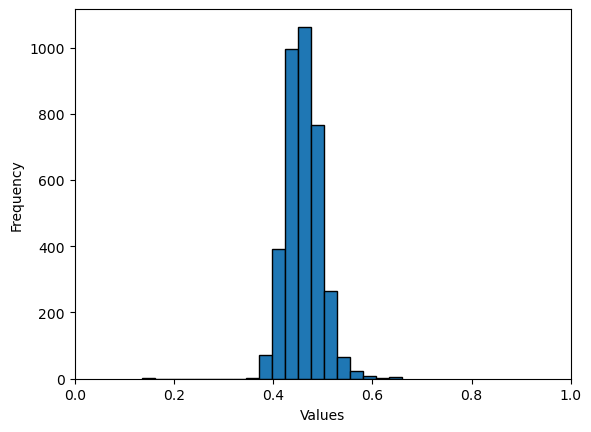

In [212]:
plt.hist(fold_probs_label_0, bins=20, edgecolor='black')

# 3. Add labels (optional but helpful)
plt.xlabel('Values')
plt.ylabel('Frequency')
plt.xlim(0,1)

# 4. Show the plot
plt.show()

In [ ]:
# the recall and precision array are in a decreased form 
# the probabailties and the true labels correspond to each other 
# the above two are not itnerconnected though

# precision and recall are calculated with the positive class as your target

In [ ]:
# the problem is that we do have a lot of negative points in the max prob space as well. because of that, we can get a lot of precision values for the same recall.
# technically the precision is decreasing possibly becasue there are less and less label 1's as the recall icnreases which means there are less and less label 1's as the prob threshold icnreases

#### checking the ratio of 1's and 0's

In [ ]:
# the recall talks abotu the 1's that are there, but you could have a lot more 0's in the 90s recall part which causes the precision to stay high

In [197]:
#  43 percent threshold - 90 percent recall



# btw 0.477 and 0.448 - between 60 and 80 percent recall

In [202]:
labels_before_43 = true_labels[fold_probs<=0.43]

In [207]:
labels_before_43

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [208]:
sum(labels_before_43 )/len(labels_before_43 )

np.float64(0.019756838905775075)

In [215]:
# labels_more_49 = fold_probs>=0.44
laebls_less_51 = fold_probs>=0.43
# labels_other = true_labels[labels_more_49 & laebls_less_51]
labels_other = true_labels[ laebls_less_51]

In [216]:
sum(labels_other)/len(labels_other)

np.float64(0.039834289356277884)

In [ ]:
# the more actual 1's packed in the eariler thresholds , the better the precision right...so we saw if there was like realitvely less no fo packed 1's relative to 0's...this way the precision will not significalty decrease...it oucld remain the same or increase. 
# the no of 1's in those two threshold blocks is the same right but still the decrease is not the same...could be cause of the no of 0'scipy


# using scikit learns official implementation 



### validating the implementation before implementing 

In [117]:
import pickle as pl
with open('/Users/adityagoyal/Desktop/Research - yin li/timeseries_project/timeseries_with_chronos/experiment_files/results_3d_focal.pkl','rb') as f: 
    results = pl.load(f)

In [118]:
results.keys()

dict_keys(['avg', 'std', 'fold_metrics', 'fold_curve_data', 'cumulative_curves', 'fold_probabilities', 'curve_output_dir', 'loss_type', 'gamma'])

In [ ]:
_save_cumulative_roc(results['fold_probabilities']['roc_curves'], "./",5)